--- Step 1: Loading Raw Data Files ---
Cleaned 0 sentinel '-1' values as NaNs in agronomic_socio
Cleaned 0 sentinel '-1' values as NaNs in agronomic_met
Cleaned 4657 sentinel '-1' values as NaNs in eggproduction
Cleaned 14962 sentinel '-1' values as NaNs in meatproduction
Cleaned 24911 sentinel '-1' values as NaNs in milkproduction

--- Step 2: Merging Livestock Data into Socioeconomic Matrix ---
Successfully created and saved new merged dataset: agronomic_socio_livestock_extended.csv (Shape: (18060, 174))

--- Step 3: Generating Advanced EDA Visualizations & Outlier Checks ---


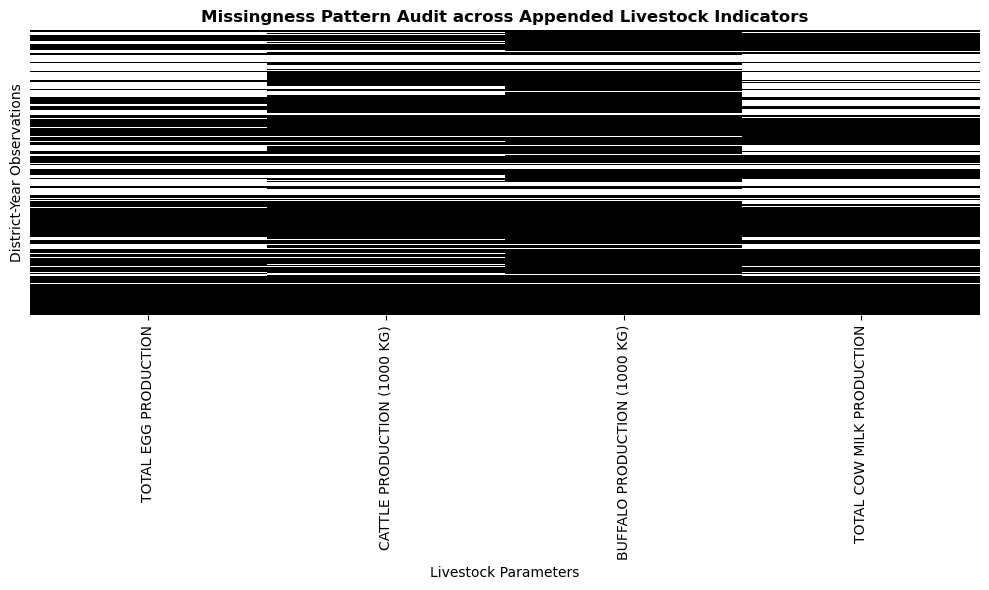

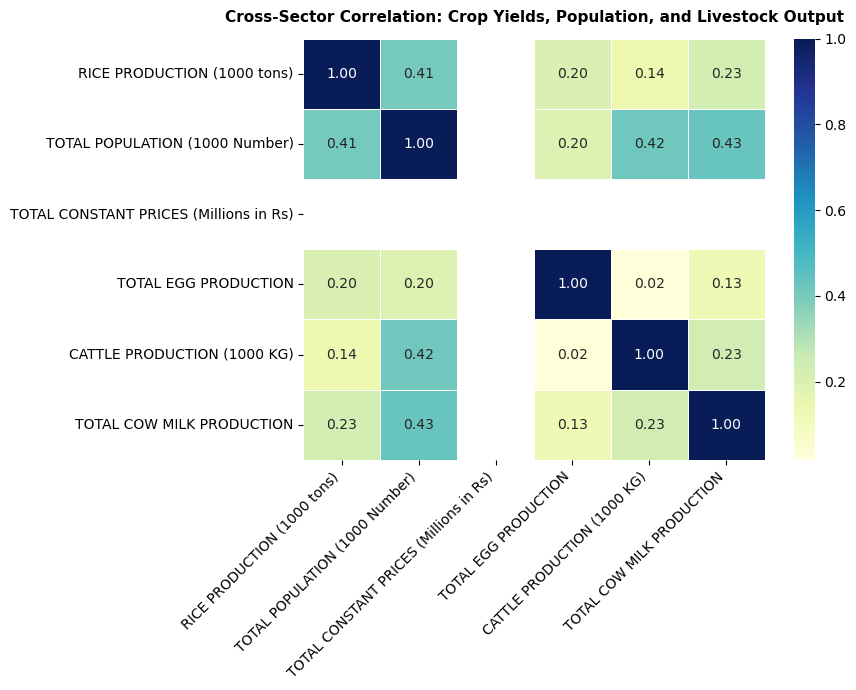


--- Step 4: Training, Tuning & Evaluating Predictive Models (Rice Yield) ---

[Baseline Model: Historical Mean]
  -> RMSE: 1084.63 Kg/ha
  -> MAE:  868.57 Kg/ha
  -> R²:   -0.0002

Training Random Forest Regressor (Controlling tree depth & estimators)...

[Candidate Model: Random Forest Regressor]
  -> RMSE: 447.64 Kg/ha
  -> MAE:  307.56 Kg/ha
  -> R²:   0.8296

Result: Random Forest reduced RMSE by 58.7% compared to the historical mean baseline!


In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# ==========================================
# PART 1: DATA HANDLING & LIVESTOCK MERGING
# ==========================================
print("--- Step 1: Loading Raw Data Files ---")
df_socio = pd.read_csv("agronomic_socio_final.csv")
df_met = pd.read_csv("agronomic_met_extinput_final.csv")
df_egg = pd.read_csv("eggproductionlivestock.csv")
df_meat = pd.read_csv("meatproductionlivestock.csv")
df_milk = pd.read_csv("milkproductionlivestock.csv")


def clean_sentinels(df, name):
  numeric_cols = df.select_dtypes(include=[np.number]).columns
  missing_before = (df[numeric_cols] == -1).sum().sum()
  df[numeric_cols] = df[numeric_cols].replace(-1, np.nan)
  print(
      f"Cleaned {missing_before} sentinel '-1' values as NaNs in {name}"
  )
  return df


df_socio = clean_sentinels(df_socio, "agronomic_socio")
df_met = clean_sentinels(df_met, "agronomic_met")
df_egg = clean_sentinels(df_egg, "eggproduction")
df_meat = clean_sentinels(df_meat, "meatproduction")
df_milk = clean_sentinels(df_milk, "milkproduction")

print(
    "\n--- Step 2: Merging Livestock Data into Socioeconomic Matrix ---"
)
df_socio_extended = df_socio.merge(
    df_egg[["Dist Code", "Year", "TOTAL PRODUCTION (Lakh Number)"]].rename(
        columns={"TOTAL PRODUCTION (Lakh Number)": "TOTAL EGG PRODUCTION"}
    ),
    on=["Dist Code", "Year"],
    how="left",
)

df_socio_extended = df_socio_extended.merge(
    df_meat[
        [
            "Dist Code",
            "Year",
            "CATTLE PRODUCTION (1000 KG)",
            "BUFFALO PRODUCTION (1000 KG)",
        ]
    ],
    on=["Dist Code", "Year"],
    how="left",
)

df_socio_extended = df_socio_extended.merge(
    df_milk[
        ["Dist Code", "Year", "TOTAL COW PRODUCTION (1000 tons)"]
    ].rename(
        columns={
            "TOTAL COW PRODUCTION (1000 tons)": "TOTAL COW MILK PRODUCTION"
        }
    ),
    on=["Dist Code", "Year"],
    how="left",
)

output_filename = "agronomic_socio_livestock_extended.csv"
df_socio_extended.to_csv(output_filename, index=False)
print(
    f"Successfully created and saved new merged dataset: {output_filename}"
    f" (Shape: {df_socio_extended.shape})"
)

# ==========================================
# PART 2: UNIQUE EDA & VISUALIZATIONS
# ==========================================
print(
    "\n--- Step 3: Generating Advanced EDA Visualizations & Outlier Checks ---"
)

plt.figure(figsize=(10, 6))
livestock_cols = [
    "TOTAL EGG PRODUCTION",
    "CATTLE PRODUCTION (1000 KG)",
    "BUFFALO PRODUCTION (1000 KG)",
    "TOTAL COW MILK PRODUCTION",
]
missing_matrix = df_socio_extended[livestock_cols].isnull()
sns.heatmap(
    missing_matrix,
    cbar=False,
    cmap="binary",
    yticklabels=False,
)
plt.title(
    "Missingness Pattern Audit across Appended Livestock Indicators",
    fontsize=12,
    weight="bold",
)
plt.xlabel("Livestock Parameters", fontsize=10)
plt.ylabel("District-Year Observations", fontsize=10)
plt.tight_layout()
plt.savefig("livestock_missingness_audit.png", dpi=300)
plt.show()

plt.figure(figsize=(9, 7))
corr_cols = [
    "RICE PRODUCTION (1000 tons)",
    "TOTAL POPULATION (1000 Number)",
    "TOTAL CONSTANT PRICES (Millions in Rs)",
    "TOTAL EGG PRODUCTION",
    "CATTLE PRODUCTION (1000 KG)",
    "TOTAL COW MILK PRODUCTION",
]
corr_matrix = df_socio_extended[corr_cols].corr()
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    linewidths=0.5,
)
plt.title(
    "Cross-Sector Correlation: Crop Yields, Population, and Livestock Output",
    fontsize=11,
    weight="bold",
    pad=12,
)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("cross_sector_correlation_heatmap.png", dpi=300)
plt.show()

# ==========================================
# PART 3: MODELING, TUNING & EVALUATION
# ==========================================
print(
    "\n--- Step 4: Training, Tuning & Evaluating Predictive Models (Rice"
    " Yield) ---"
)

df_model = df_met.dropna(subset=["RICE YIELD (Kg per ha)"]).copy()

exclude_cols = [
    "Dist Code",
    "Year",
    "State Code",
    "State Name",
    "Dist Name",
    "RICE YIELD (Kg per ha)",
    "RICE PRODUCTION (1000 tons)",
    "RICE AREA (1000 ha)",
]
feature_cols = [c for c in df_model.columns if c not in exclude_cols]
X = df_model[feature_cols].select_dtypes(include=[np.number]).fillna(0)
y = df_model["RICE YIELD (Kg per ha)"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

baseline_pred_array = np.full_like(y_test, fill_value=y_train.mean())
base_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred_array))
base_mae = mean_absolute_error(y_test, baseline_pred_array)
base_r2 = r2_score(y_test, baseline_pred_array)

print("\n[Baseline Model: Historical Mean]")
print(f"  -> RMSE: {base_rmse:.2f} Kg/ha")
print(f"  -> MAE:  {base_mae:.2f} Kg/ha")
print(f"  -> R²:   {base_r2:.4f}")

print(
    "\nTraining Random Forest Regressor (Controlling tree depth & estimators)..."
)
rf_model = RandomForestRegressor(
    n_estimators=100, max_depth=15, random_state=42, n_jobs=-1
)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
rf_mae = mean_absolute_error(y_test, y_pred)
rf_r2 = r2_score(y_test, y_pred)

print("\n[Candidate Model: Random Forest Regressor]")
print(f"  -> RMSE: {rf_rmse:.2f} Kg/ha")
print(f"  -> MAE:  {rf_mae:.2f} Kg/ha")
print(f"  -> R²:   {rf_r2:.4f}")

improvement_rmse = ((base_rmse - rf_rmse) / base_rmse) * 100
print(
    f"\nResult: Random Forest reduced RMSE by {improvement_rmse:.1f}% compared"
    " to the historical mean baseline!"
)